# 香港地铁路径分析

用 NetworkX 将香港地铁建模为多重图，比较 **最少乘车区间** 与 **最短距离** 两个目标。

本项目保留 2023-02-01 的原始数据快照。它展示数据读取、图建模、路径分析和可视化的完整过程；具体数据来源与建模限制见 [README](README.md)。

## 1. 准备环境

先按 README 安装 `requirements.txt`，再从头运行全部单元格。绘图使用固定种子的拓扑布局，无需 Graphviz。中文标签需要系统中文字体。

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import Markdown, display

from metro import (
    DATA_DIR, compare_routes, configure_plotting, get_transfer_stations,
    load_network, network_positions, plot_network, plot_route_comparison,
)

configure_plotting()
image_dir = DATA_DIR / "images"
image_dir.mkdir(exist_ok=True)

## 2. 从原始数据构建多重图

两个 TXT 文件实际使用 UTF-16 编码。读取时跳过空行与注释，用 `int()`、`float()` 解析数值，并检查未知线路、无效距离和重复连接。

同名站点自然共用一个节点；使用 `MultiGraph` 保留不同线路之间的平行边。每条边记录 `line_id`、`line_name`、`color` 和距离 `weight`，每个节点记录所属线路集合。

In [2]:
graph = load_network()
transfer_stations = get_transfer_stations(graph)

display(Markdown(
    f"**数据快照：{graph.graph['snapshot']}**\n\n"
    f"- 线路：{len(graph.graph['lines'])} 条\n"
    f"- 建模节点：{graph.number_of_nodes()} 个\n"
    f"- 站间连接（保留平行边）：{graph.number_of_edges()} 条\n"
    f"- 多线路换乘站：{len(transfer_stations)} 个\n"
    f"- 全图连通：{'是' if nx.is_connected(graph) else '否'}"
))

**数据快照：2023-02-01**

- 线路：10 条
- 建模节点：96 个
- 站间连接（保留平行边）：112 条
- 多线路换乘站：21 个
- 全图连通：是

### 显式保留线路归属

油麻地与旺角之间同时存在荃湾线和观塘线连接。两条边分别保留线路属性，因此既能识别线路，也能分别绘制颜色。

换乘站按“属于多条线路”识别，而不是按连接方向的数量判断。上水、将军澳等同一线路的分支节点不会因此被标成跨线路换乘站。这里的标注不等同于计算某条行程的换乘次数。

In [3]:
for edge in graph["油麻地"]["旺角"].values():
    print(f"{edge['line_name']}：油麻地 ↔ 旺角，距离权重 {edge['weight']:.2f}")

for station in ("金钟", "旺角", "上水", "将军澳"):
    names = [graph.graph["lines"][code]["name"] for code in sorted(graph.nodes[station]["lines"])]
    print(f"{station}：{'、'.join(names)}；多线路换乘站：{'是' if station in transfer_stations else '否'}")

荃湾线：油麻地 ↔ 旺角，距离权重 0.76
观塘线：油麻地 ↔ 旺角，距离权重 0.76
金钟：荃湾线、港岛线、南港岛线、东铁线；多线路换乘站：是
旺角：荃湾线、观塘线；多线路换乘站：是
上水：东铁线；多线路换乘站：否
将军澳：将军澳线；多线路换乘站：否


## 3. 网络拓扑可视化

线路按原始颜色显示，共线路段使用不同弧线。浅红色节点为模型中的多线路换乘站。

**图中位置为拓扑布局，不代表地理位置；图上边长也不代表实际距离。** 两种路径复用同一套位置，方便对比。

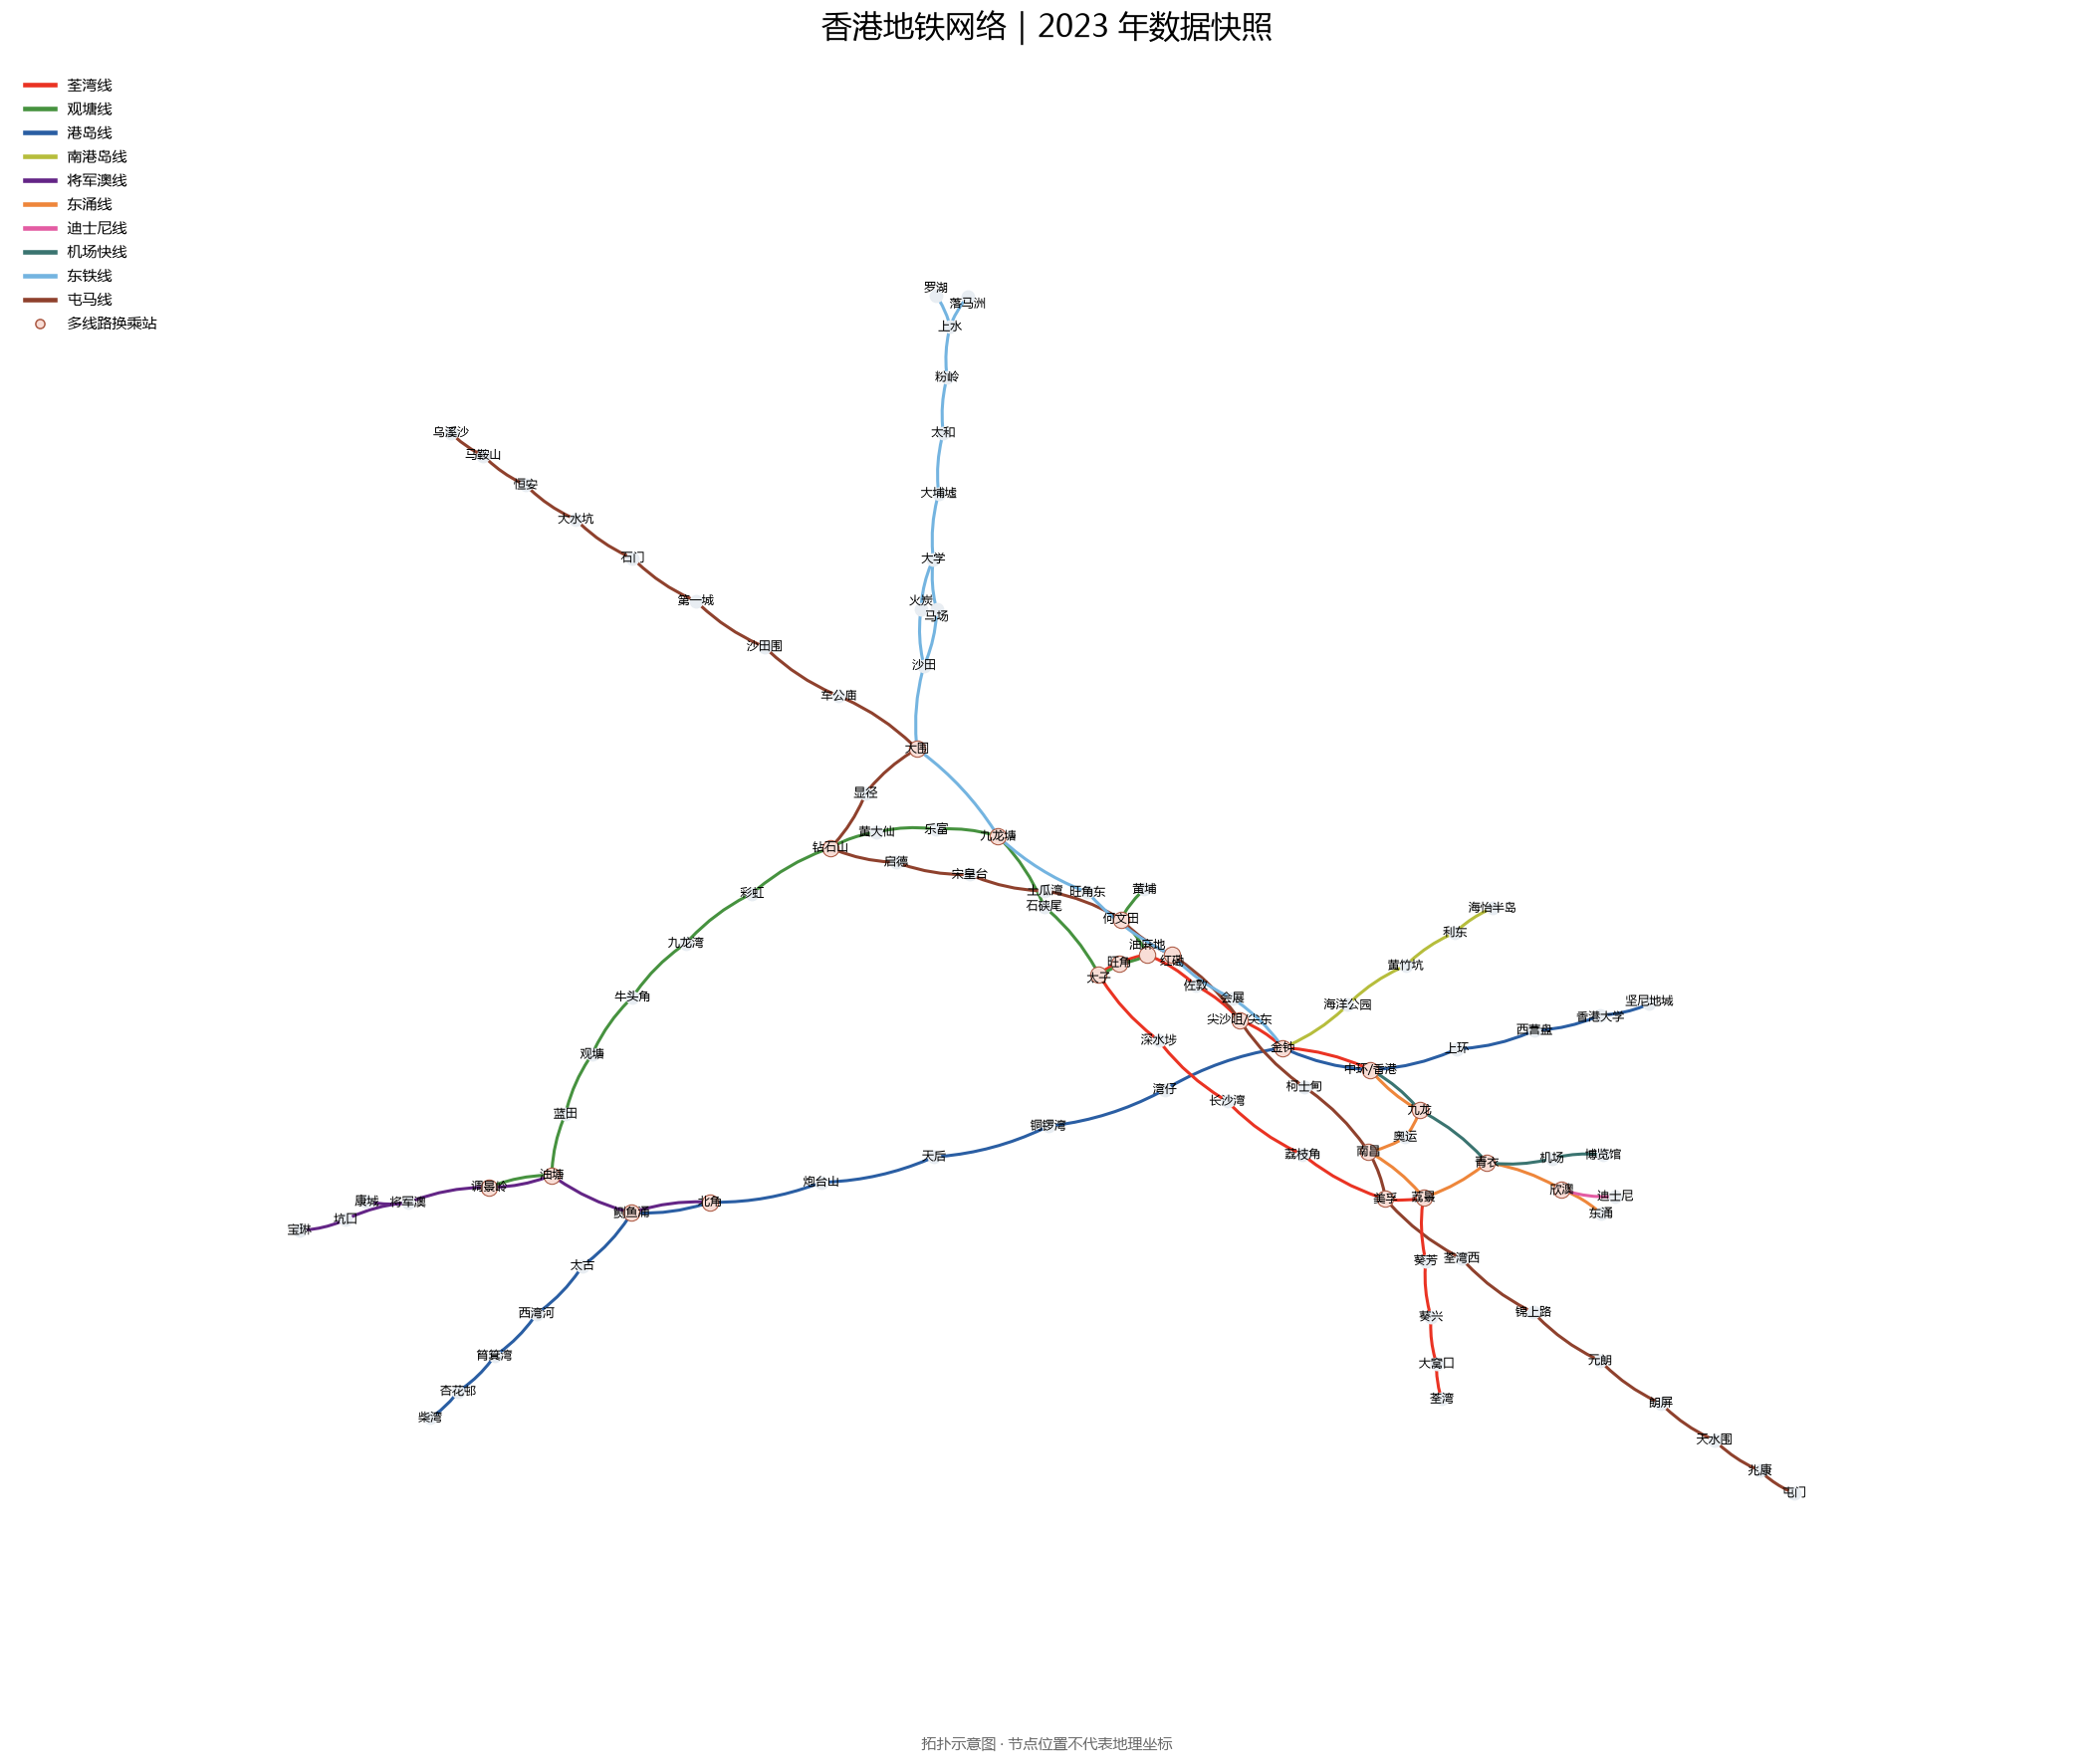

In [4]:
positions = network_positions(graph)
fig = plot_network(graph, positions)
fig.savefig(image_dir / "network.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. 比较路径策略

- **最少区间**：将每段站间连接视为一步，使用无权最短路径（BFS）。
- **最短距离**：使用站间距离权重，运行 Dijkstra。

“站点数”包含起终点；“乘车区间数”等于站点数减一。距离由数据自动累计；同一对站点的多条平行边取最小权重。最少区间存在并列解时，返回其中一条，不额外优化距离。

修改下方的 `source`、`target` 即可查询其他站点。节点名采用原始数据写法，例如 `中环/香港`。

In [5]:
source = "油塘"
target = "青衣"
results = compare_routes(graph, source, target)

rows = [
    "| 策略 | 乘车区间数 | 站点数（含起终点） | 距离权重 |",
    "| --- | ---: | ---: | ---: |",
]
for result in results:
    rows.append(
        f"| {result['strategy']} | {result['segment_count']} | "
        f"{result['station_count']} | {result['distance']:.2f} |"
    )
display(Markdown("\n".join(rows)))

for result in results:
    display(Markdown(f"**{result['strategy']}**：" + " → ".join(result["path"])))

| 策略 | 乘车区间数 | 站点数（含起终点） | 距离权重 |
| --- | ---: | ---: | ---: |
| 最少区间 | 10 | 11 | 20.89 |
| 最短距离 | 17 | 18 | 19.00 |

**最少区间**：油塘 → 鲗鱼涌 → 北角 → 炮台山 → 天后 → 铜锣湾 → 湾仔 → 金钟 → 中环/香港 → 九龙 → 青衣

**最短距离**：油塘 → 蓝田 → 观塘 → 牛头角 → 九龙湾 → 彩虹 → 钻石山 → 黄大仙 → 乐富 → 九龙塘 → 石硖尾 → 太子 → 深水埗 → 长沙湾 → 荔枝角 → 美孚 → 荔景 → 青衣

### 在同一网络上分别显示路线

左右图使用同一布局，每张图只高亮一种策略及其经过的站点，避免红蓝路线重叠覆盖。导出的图片也用于 README。

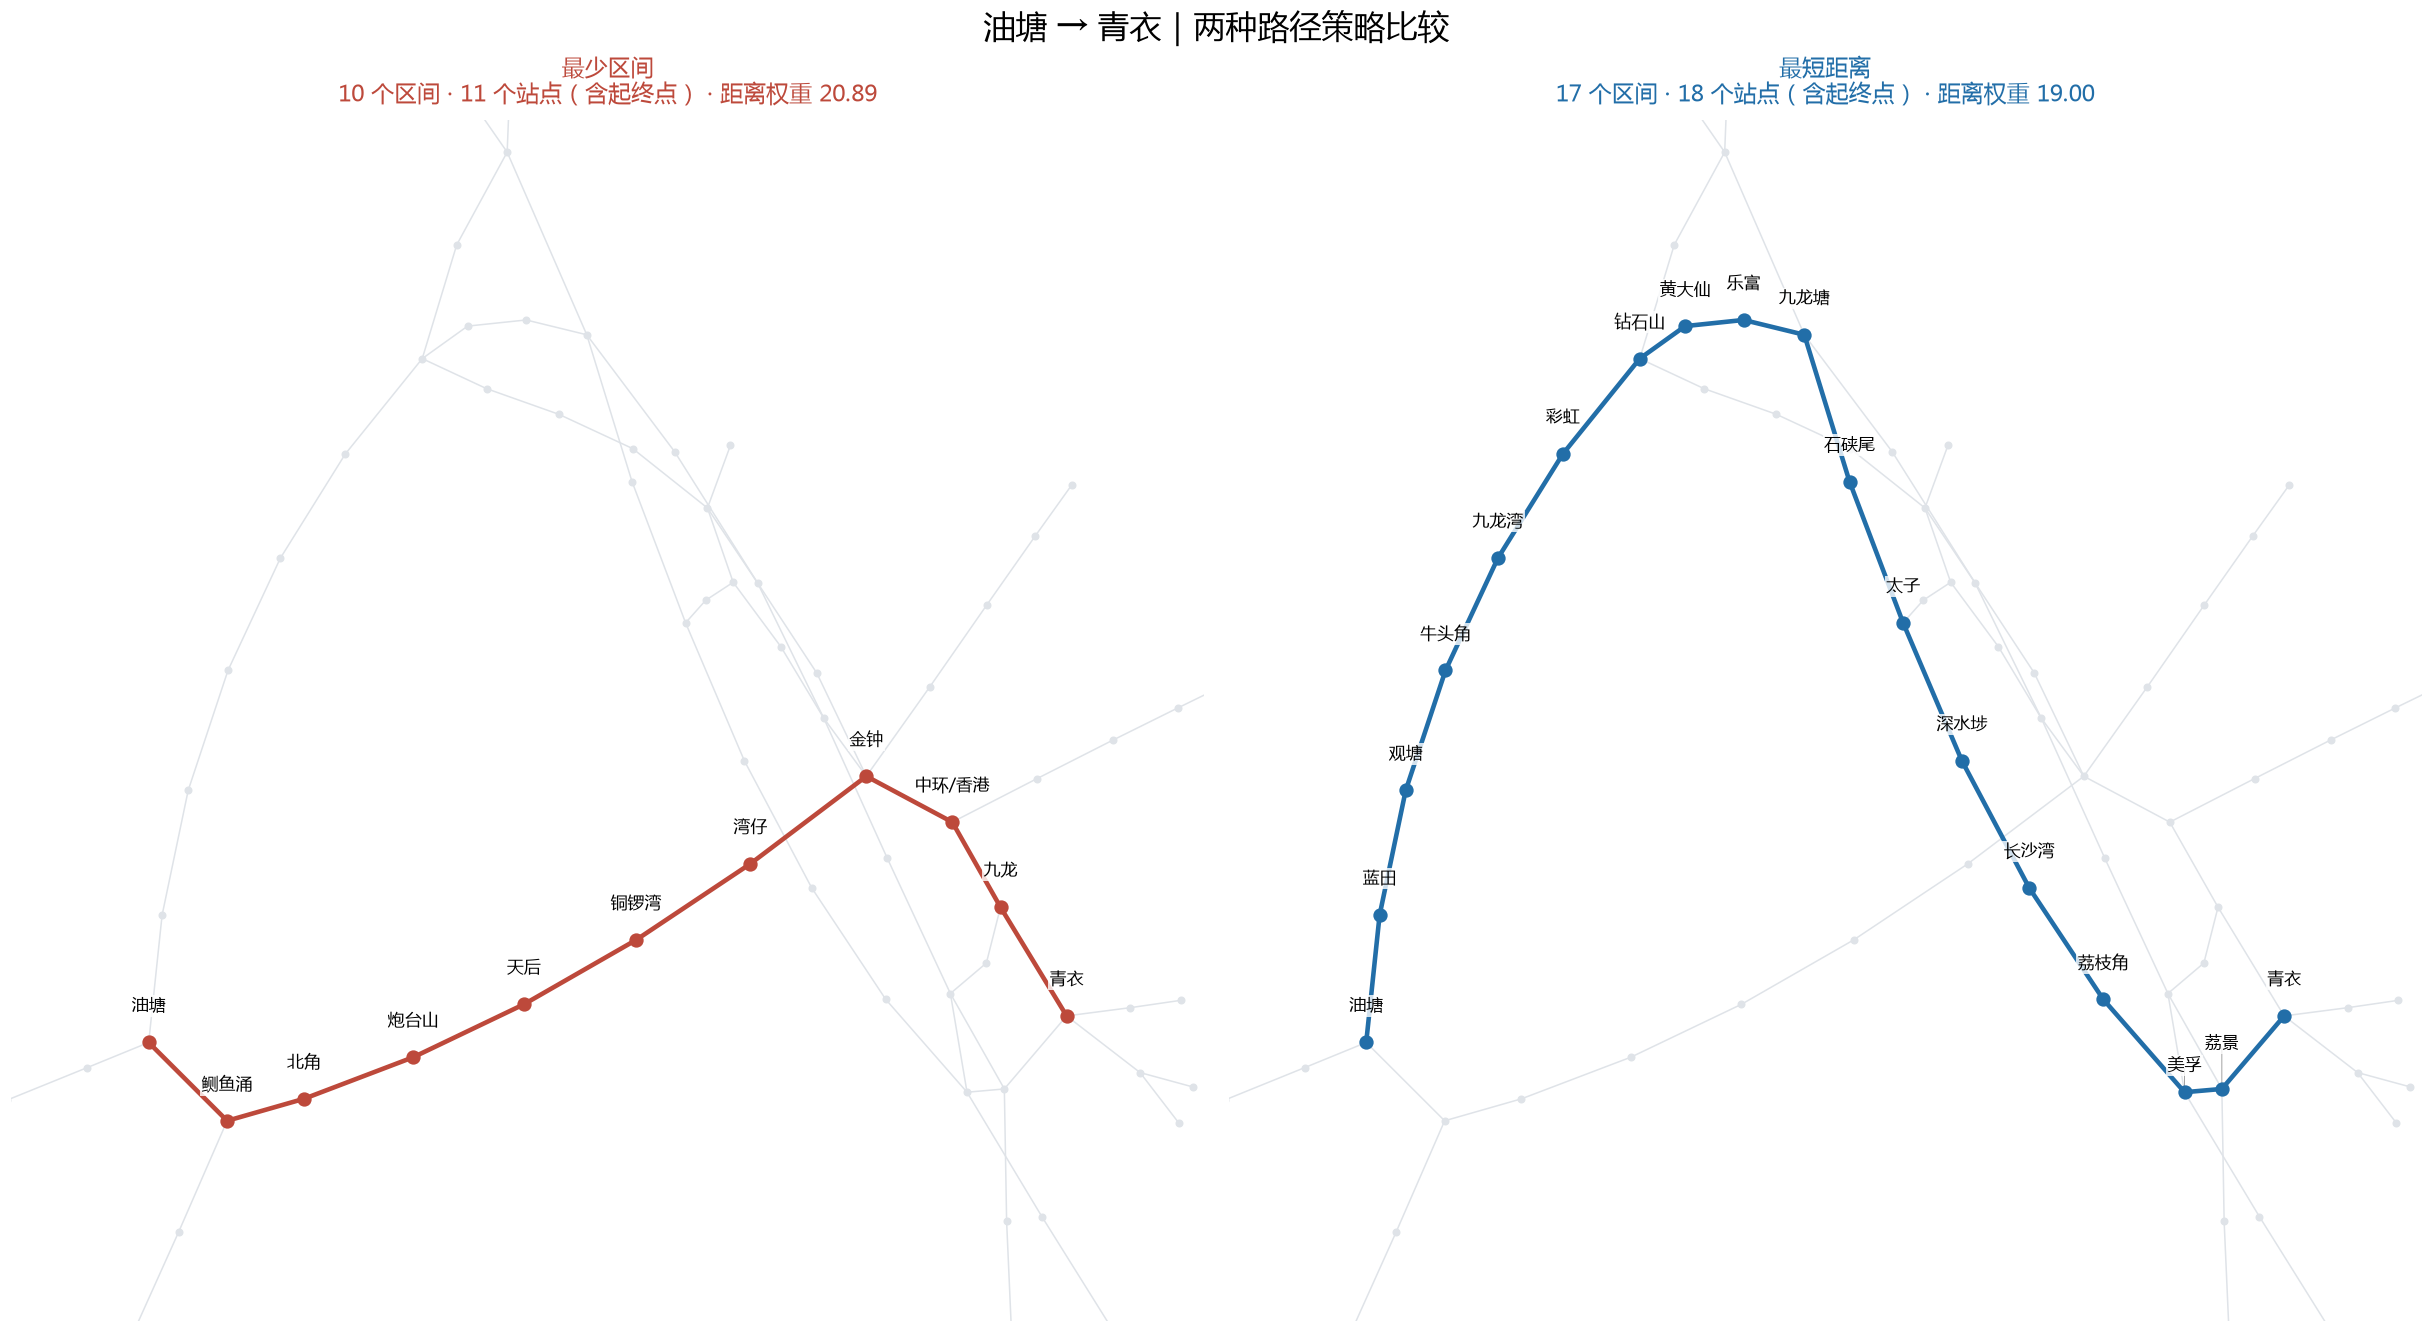

In [6]:
fig = plot_route_comparison(graph, positions, results)
fig.savefig(image_dir / "route_comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. 结果解释与边界

在默认的油塘 → 青衣示例中，最少区间路线为 10 个区间、距离权重 20.89；最短距离路线为 17 个区间、距离权重 19.00。不同优化目标对应不同路线。

本模型沿用原项目的假设：

- 2023 年数据没有随当前线路更新，距离权重沿用原始数值。
- 中环/香港、尖沙咀/尖东各自合并为一个节点，未计步行距离。
- 图为无向图，未计算候车、换乘、班次、票价和运行时间，也未建模机场快线的乘车与换乘限制。
- 马场站相关连接保留了原始 `0.001` 权重调整，不能替代特殊班次处理。

因此，这里的最短距离结果不能解释为最快到达或实时出行推荐。后续若加入最少换乘策略，需要进一步记录行程中实际选择的线路状态。

核心行为可在仓库根目录通过 `python -m unittest discover -s tests -v` 检查。